# Diseño de vigas de hormigón presforzado

Diseño a flexión:

1. Datos de entrada (cargas desde `Datos/cargas.json` o manuales)
2. **Predimensionamiento** y **sección T inicial** (iteración 1)
3. **Sección transversal**: iteración actual
4. Propiedades mecánicas
5. Cargas y momentos en el centro de la luz
6. Diseño definitivo: $F_0$, $F$ y $e$ (excentricidad no restringida o restringida)
7. Análisis de la sección en $L/2$
8. Verificación de esfuerzos admisibles (**tracción = 0**)
9. Eficiencia de la sección $Q$
10. **Registro de iteraciones** (botón *Guardar iteración* y tabla resumen)
11. **Cable resultante** parabólico y **curvas límite**
12. **Torones** (modo manual): número, posición y verificación de la resultante
13. Validez del diseño
14. Informe en LaTeX

**Unidades:** Sistema MKS

**Signos:** compresión **negativa (−)**; excentricidades positivas **hacia abajo** del c.g.; $x$ desde el apoyo izquierdo.

> **Cómo iterar:**
> 1. Modifique la sección en el paso 3.
> 2. Ejecute **Run All**.
> 3. Revise el paso 10 y presione **Guardar iteración**.
> 4. Si la sección no cumple, el cuaderno se detiene en el paso 10: vuelva al punto 1. Si cumple, continúa con el cable y los torones.

In [1]:
%matplotlib inline
import importlib
import matplotlib.pyplot as plt
try:
    import ipywidgets as widgets      # botón Guardar iteración
    HAY_WIDGETS = True
except ImportError:
    HAY_WIDGETS = False
from IPython.display import Markdown, display, clear_output
import sys
if 'Core' not in sys.path:
    sys.path.insert(0, 'Core')          # motores de cálculo (.py) en la carpeta Core
import presforzado
importlib.reload(presforzado)   # toma cambios del módulo sin reiniciar el kernel
import iteraciones
importlib.reload(iteraciones)
from presforzado import (Datos, Seccion, Poligono, rectangulo, poligono, toron,
                         seccion_T, seccion_I, seccion_cajon,
                         predimensionar, comparar_predim, seccion_T_predim, obtener_cargas, disenar,
                         curvas_limite, verificar_torones,
                         dibujar_seccion, dibujar_esfuerzos, dibujar_curvas_limite, dibujar_torones)
from iteraciones import Registro, veredicto_md

def mostrar(texto):
    display(Markdown(texto))

class DisenoDetenido(Exception):
    '''Detiene 'Run All' con un mensaje limpio (sin traceback).'''
    def _render_traceback_(self):
        return ['\033[1;31m' + str(self) + '\033[0m']

def detener(mensaje):
    raise DisenoDetenido(mensaje)

def tabla(encabezados, filas):
    t = '| ' + ' | '.join(encabezados) + ' |\n|' + '---|' * len(encabezados) + '\n'
    return t + '\n'.join('| ' + ' | '.join(str(c) for c in f) + ' |' for f in filas)

def desarrollo_esfuerzos(p, F0, F, e, MGc, MTc, esf):
    fi1, fi2 = esf['inicial']; ff1, ff2 = esf['final']
    return f'''
*Etapa inicial ($F_0 + M_G$):*

- $f_1 = -\\dfrac{{{F0:,.2f}}}{{{p.A:,.2f}}} + \\dfrac{{({F0:,.2f})({e:.2f})}}{{{p.S1:,.2f}}} - \\dfrac{{{MGc:,.0f}}}{{{p.S1:,.2f}}} = $ **{fi1:.2f} kg/cm²**
- $f_2 = -\\dfrac{{{F0:,.2f}}}{{{p.A:,.2f}}} - \\dfrac{{({F0:,.2f})({e:.2f})}}{{{p.S2:,.2f}}} + \\dfrac{{{MGc:,.0f}}}{{{p.S2:,.2f}}} = $ **{fi2:.2f} kg/cm²**

*Etapa final ($F + M_T$):*

- $f_1 = -\\dfrac{{{F:,.2f}}}{{{p.A:,.2f}}} + \\dfrac{{({F:,.2f})({e:.2f})}}{{{p.S1:,.2f}}} - \\dfrac{{{MTc:,.0f}}}{{{p.S1:,.2f}}} = $ **{ff1:.2f} kg/cm²**
- $f_2 = -\\dfrac{{{F:,.2f}}}{{{p.A:,.2f}}} - \\dfrac{{({F:,.2f})({e:.2f})}}{{{p.S2:,.2f}}} + \\dfrac{{{MTc:,.0f}}}{{{p.S2:,.2f}}} = $ **{ff2:.2f} kg/cm²**
'''

def tabla_verificacion(res, esf, ver):
    filas = []
    for etapa in ('inicial', 'final'):
        lim = res.limites[etapa]
        for fibra, f in zip(('1', '2'), esf[etapa]):
            filas.append([etapa.capitalize(), f'$f_{fibra}$', f'{f:.2f}', f"{lim['comp']:.2f}", '0.00',
                          '✓ Cumple' if ver[(etapa, fibra)] else '✗ **NO CUMPLE**'])
    return tabla(['Etapa', 'Fibra', 'f [kg/cm²]', 'Comp. adm.', 'Tracc. adm.', 'Estado'], filas)


## 1. Datos de entrada

In [2]:
# --- Cargas sobre la viga ------------------------------------------------------
usar_json   = True            # True: lee Datos/cargas.json (generado por Cargas.ipynb) · False: valores manuales
ruta_cargas = 'Datos/cargas.json'
cargas_manual = dict(         # se usan si usar_json = False o si no se encuentra cargas.json
    L          = 35.0,    # luz del puente [m]
    q_losa     = 1200.0,  # [kg/m]
    q_acera    = 210.0,   # [kg/m]
    q_parantes = 103.5,   # postes y pasamanos [kg/m]
    q_asfalto  = 287.5,   # carpeta asfáltica [kg/m]
    q_L        = 800.0,   # carga viva [kg/m]
)
cargas_in, origen_cargas = obtener_cargas(usar_json, ruta_cargas, cargas_manual)

# --- Hormigón, presfuerzo y predimensionamiento ----------------------------------
datos = Datos(
    **cargas_in,
    fc         = 420.0,   # f'c del hormigón de la viga [kg/cm²]
    perdidas   = 18.0,    # pérdidas de presfuerzo [%]
    d2         = 17.0,    # recubrimiento en L/2 [cm]
    gamma_c    = 2400.0,  # peso específico del hormigón [kg/m³]
    fci_factor = 0.70,    # f'ci = 0.70·f'c
    qG_asumido = 1000.0,  # peso propio asumido [kg/m]  (puentes L≈30 m: qG ≈ 1 T/m)
    k_L        = 16,      # h = L/k     (16 < k < 22 vigas simplemente apoyadas; cubiertas T: 30 < k < 40)
    k_M        = 0.40,    # h = k·√M    (0.38 < k < 0.43;  h en cm, M en kg-m)
    es_puente  = True,    # aplica h = L/25 + 10 cm (puentes de 20 m a 40 m)
)

# --- Sección T inicial del predimensionamiento (iteración 1) ---------------------
t_predim  = 16.0              # espesor del ala [cm]
bw_predim = 16.0              # ancho del alma [cm]

mostrar(origen_cargas)
mostrar(tabla(['Carga', 'Valor'], [
    ['Luz $L$', f'{datos.L:g} m'], ['$q_{losa}$', f'{datos.q_losa:,.2f} kg/m'],
    ['$q_{acera}$', f'{datos.q_acera:,.2f} kg/m'], ['$q_{parantes}$', f'{datos.q_parantes:,.2f} kg/m'],
    ['$q_{asfalto}$', f'{datos.q_asfalto:,.2f} kg/m'], ['**$q_D$**', f'**{datos.qD:,.2f} kg/m**'],
    ['$q_L$ (carga viva)', f'{datos.q_L:,.2f} kg/m']]))

Cargas leídas de **Datos/cargas.json** (generado por `Cargas.ipynb`, 2026-11-18 15:03).

| Carga | Valor |
|---|---|
| Luz $L$ | 35 m |
| $q_{losa}$ | 1,260.00 kg/m |
| $q_{acera}$ | 128.00 kg/m |
| $q_{parantes}$ | 17.55 kg/m |
| $q_{asfalto}$ | 241.50 kg/m |
| **$q_D$** | **1,647.05 kg/m** |
| $q_L$ (carga viva) | 1,200.00 kg/m |

## 2. Predimensionamiento

Se usa el peso propio asumido $q_{G,asum}$ para estimar los momentos.

**Altura** (se adopta el **promedio** de los criterios):

| Criterio | Fórmula |
|---|---|
| En función de la luz | $h = L/k$ |
| Puentes de 20 m a 40 m | $h = L/25 + 10$ cm |
| En función de la luz y la carga | $h = k\sqrt{M}$ |
| Relación luz-altura | $h = 0.07\,L$ |

**Área de hormigón** ($f_c = 0.45 f'_c$, $M_L = M_T - M_G$):
- $M_G/M_T < 0.20$: $A_c = \dfrac{4 M_L}{f_c\,h}$  ·  $M_G/M_T > 0.30$: $A_c = \dfrac{3 M_T}{f_c\,h}$  ·  entre ambos: el mayor.

**Ancho de alma:** $b_w = 16$ a $20$ cm, el menor posible.

In [3]:
pre = predimensionar(datos)
d = datos
mostrar(f'''
- $q_T = q_D + q_{{G,asum}} + q_L = {d.qD:,.2f} + {d.qG_asumido:,.2f} + {d.q_L:,.2f} = {pre.qT:,.2f}$ kg/m
- $M_G = \\dfrac{{({d.qG_asumido:,.2f})({d.L})^2}}{{8}} = {pre.MG:,.2f}$ kg‑m  ·  $M_T = \\dfrac{{({pre.qT:,.2f})({d.L})^2}}{{8}} = {pre.MT:,.2f}$ kg‑m  ·  $M_G/M_T = {pre.relacion:.3f}$
''')
mostrar(tabla(['Criterio', 'Cálculo', 'h [cm]'],
              [[c[0], c[1], f'{c[2]:.2f}'] for c in pre.criterios] +
              [['**Promedio (recomendado)**', '', f'**{pre.h_prom:.2f}**']]))
for a in pre.avisos:
    mostrar(f'⚠ {a}')
mostrar(f'''
- $f_c = 0.45\\,({d.fc:.0f}) = {pre.fc_adm:.2f}$ kg/cm²  ·  $M_L = {pre.ML:,.2f}$ kg‑m
- $A_{{c,1}} = \\dfrac{{4\\,M_L}}{{f_c\\,h}} = \\dfrac{{4({pre.ML:,.2f}\\times10^2)}}{{({pre.fc_adm:.2f})({pre.h_prom:.2f})}} = {pre.Ac_caso1:,.2f}$ cm²
- $A_{{c,2}} = \\dfrac{{3\\,M_T}}{{f_c\\,h}} = \\dfrac{{3({pre.MT:,.2f}\\times10^2)}}{{({pre.fc_adm:.2f})({pre.h_prom:.2f})}} = {pre.Ac_caso2:,.2f}$ cm²
- {pre.caso}

### Recomendaciones para dibujar la sección
| Ítem | Recomendación |
|---|---|
| Altura $h$ | ≈ **{pre.h_prom:.1f} cm** |
| Área de hormigón $A_c$ | ≥ **{pre.Ac_req:,.0f} cm²** |
| Ancho de alma $b_w$ | **16 a 20 cm** |
''')


- $q_T = q_D + q_{G,asum} + q_L = 1,647.05 + 1,000.00 + 1,200.00 = 3,847.05$ kg/m
- $M_G = \dfrac{(1,000.00)(35.0)^2}{8} = 153,125.00$ kg‑m  ·  $M_T = \dfrac{(3,847.05)(35.0)^2}{8} = 589,079.53$ kg‑m  ·  $M_G/M_T = 0.260$


| Criterio | Cálculo | h [cm] |
|---|---|---|
| h = L/k | L/16 | 218.75 |
| h = L/25 + 10 cm | 35/25 + 0.10 | 150.00 |
| h = k·√M | 0.4·√589,080 | 307.01 |
| h = 0.07·L | 0.07·35 | 245.00 |
| **Promedio (recomendado)** |  | **230.19** |


- $f_c = 0.45\,(420) = 189.00$ kg/cm²  ·  $M_L = 435,954.53$ kg‑m
- $A_{c,1} = \dfrac{4\,M_L}{f_c\,h} = \dfrac{4(435,954.53\times10^2)}{(189.00)(230.19)} = 4,008.25$ cm²
- $A_{c,2} = \dfrac{3\,M_T}{f_c\,h} = \dfrac{3(589,079.53\times10^2)}{(189.00)(230.19)} = 4,062.08$ cm²
- 0.20 ≤ M_G/M_T ≤ 0.30 → se adopta el mayor de ambos casos

### Recomendaciones para dibujar la sección
| Ítem | Recomendación |
|---|---|
| Altura $h$ | ≈ **230.2 cm** |
| Área de hormigón $A_c$ | ≥ **4,062 cm²** |
| Ancho de alma $b_w$ | **16 a 20 cm** |


### Sección T inicial (iteración 1)

Con la altura recomendada redondeada a 5 cm, el espesor del ala $t$ y el ancho del alma $b_w$ (datos), el ancho del ala sale de igualar el área de la T con el área requerida:

$$A_{c,req} = B\,t + (h - t)\,b_w \quad\Rightarrow\quad B = \frac{A_{c,req} - (h - t)\,b_w}{t}$$


- $h$ = 230.19 cm → redondeado a 5 cm: **h = 230 cm**
- $t$ = 16 cm  ·  $b_w$ = 16 cm
- $B = \dfrac{4,062.08 - (230 - 16)(16)}{16} = 39.88$ cm → **B = 40 cm**


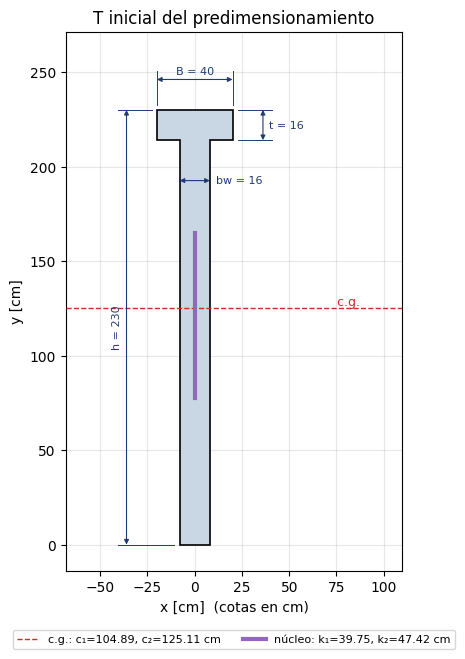

In [4]:
tp = seccion_T_predim(pre, t=t_predim, bw=bw_predim)
mostrar(f'''
- $h$ = {pre.h_prom:.2f} cm → redondeado a {tp.redondeo_h:g} cm: **h = {tp.h:g} cm**
- $t$ = {tp.t:g} cm  ·  $b_w$ = {tp.bw:g} cm
- $B = \\dfrac{{{pre.Ac_req:,.2f} - ({tp.h:g} - {tp.t:g})({tp.bw:g})}}{{{tp.t:g}}} = {tp.B_calc:.2f}$ cm → **B = {tp.B:g} cm**
''' + ('\n⚠ El área requerida se cubre casi solo con el alma: B se limitó a $b_w$.' if tp.B_calc < tp.bw else ''))
dibujar_seccion(tp.seccion, titulo='T inicial del predimensionamiento')
plt.show()

## 3. Sección transversal: iteración actual

**Iteración 1:** la T del predimensionamiento (`seccion = tp.seccion`).
**Siguientes:** escriba sus dimensiones en `seccion = ...`, ejecute **Run All**, revise el paso 10 y presione **Guardar iteración**. Repita hasta que la sección cumpla.

Coordenadas en cm, con **y = 0 en la fibra inferior**. La nomenclatura de cada cota está en la carpeta **`Instructivo/`** (`Seccion_T.png`, `Seccion_I.png`, `Seccion_Cajon.png`).

| Opción | Uso |
|---|---|
| `seccion_T(B, t, bw, h)` | Viga T |
| `seccion_I(bs, ts, bw, bi, ti, h, cs_b, cs_h, ci_b, ci_h)` | Viga I con cartelas opcionales |
| `seccion_cajon(B, h, ts, ti, tw, Bi)` | Cajón de una celda |
| `Seccion([poligono([...]), rectangulo(...), ...])` | **Cualquier forma**; `hueco=True` resta vacíos |

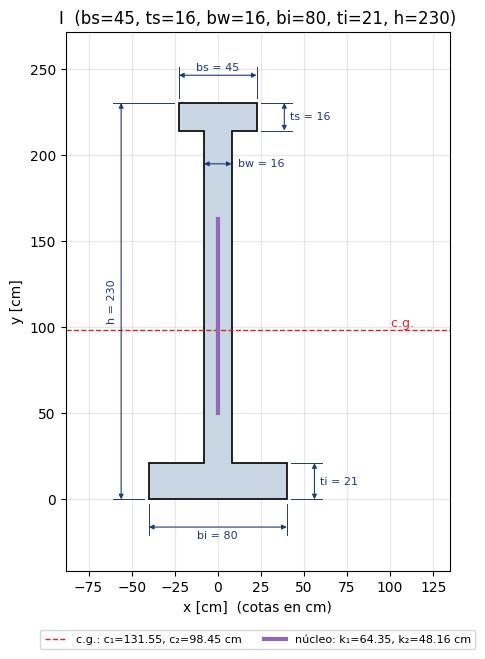

**Comparación con el predimensionamiento:**

| Ítem | Recomendado | Adoptado | Observación |
|---|---|---|---|
| Altura h | 230.2 cm | 230.0 cm | ✓ -0.1 % respecto al promedio |
| Área de hormigón A_c | ≥ 4,062 cm² | 5,488 cm² | ✓ suficiente |
| Ancho de alma b_w | 16 a 20 cm | 16 cm | ✓ dentro del rango |

In [5]:
seccion = tp.seccion          # iteración 1: T del predimensionamiento

# Iteraciones siguientes: escriba aquí sus dimensiones (ver carpeta Instructivo/).
# Ejemplo resuelto: la iteración 2 es una sección I que cumple (borre o comente esta línea para empezar de nuevo).
seccion = seccion_I(bs=45, ts=16, bw=16, bi=80, ti=21, h=230)

dibujar_seccion(seccion)
plt.show()
mostrar('**Comparación con el predimensionamiento:**\n\n' +
        tabla(['Ítem', 'Recomendado', 'Adoptado', 'Observación'], comparar_predim(pre, seccion)))

## 4. Propiedades mecánicas

$$c_1 = y_{sup} - \bar y \qquad c_2 = \bar y - y_{inf} \qquad S_1 = \frac{I}{c_1} \qquad S_2 = \frac{I}{c_2} \qquad k_1 = \frac{I}{A\,c_2} \qquad k_2 = \frac{I}{A\,c_1}$$

In [6]:
res = disenar(seccion, datos)
p = res.prop
mostrar(tabla(['Propiedad', 'Valor'], [
    ['$A$', f'{p.A:,.2f} cm²'], ['$h$', f'{p.h:,.2f} cm'],
    ['$c_1$ (c.g. → fibra superior)', f'{p.c1:,.2f} cm'], ['$c_2$ (c.g. → fibra inferior)', f'{p.c2:,.2f} cm'],
    ['$I$', f'{p.I:,.2f} cm⁴'], ['$S_1$', f'{p.S1:,.2f} cm³'], ['$S_2$', f'{p.S2:,.2f} cm³'],
    ['$k_1 = I/(A c_2)$', f'{p.k1:,.2f} cm'], ['$k_2 = I/(A c_1)$', f'{p.k2:,.2f} cm'],
    ['$r^2 = I/A$', f'{p.r2:,.2f} cm²']]))

| Propiedad | Valor |
|---|---|
| $A$ | 5,488.00 cm² |
| $h$ | 230.00 cm |
| $c_1$ (c.g. → fibra superior) | 131.55 cm |
| $c_2$ (c.g. → fibra inferior) | 98.45 cm |
| $I$ | 34,768,806.13 cm⁴ |
| $S_1$ | 264,310.74 cm³ |
| $S_2$ | 353,144.82 cm³ |
| $k_1 = I/(A c_2)$ | 64.35 cm |
| $k_2 = I/(A c_1)$ | 48.16 cm |
| $r^2 = I/A$ | 6,335.42 cm² |

## 5. Cargas y momentos en el centro de la luz

$$q_G = A\,\gamma_c \qquad q_D = q_{losa} + q_{acera} + q_{parantes} + q_{asfalto} \qquad q_T = q_D + q_G + q_L \qquad M(x) = \frac{q\,x\,(L-x)}{2} \;\Rightarrow\; M\!\left(\tfrac{L}{2}\right) = \frac{q\,L^2}{8}$$

In [7]:
mostrar(f'''
- $q_G = ({p.A:,.2f}\\ \\text{{cm}}^2)(10^{{-4}})({d.gamma_c:,.0f}\\ \\text{{kg/m}}^3) = $ **{res.qG:,.2f} kg/m**
- $q_D = {d.q_losa:,.2f} + {d.q_acera:,.2f} + {d.q_parantes:,.2f} + {d.q_asfalto:,.2f} = $ **{res.qD:,.2f} kg/m**
- $q_T = {res.qD:,.2f} + {res.qG:,.2f} + {d.q_L:,.2f} = $ **{res.qT:,.2f} kg/m**
- $M_G = \\dfrac{{({res.qG:,.2f})({d.L})^2}}{{8}} = $ **{res.MG:,.2f} kg‑m**
- $M_T = \\dfrac{{({res.qT:,.2f})({d.L})^2}}{{8}} = $ **{res.MT:,.2f} kg‑m**
- $M_G / M_T = $ **{res.MG / res.MT:.2f}**
''')


- $q_G = (5,488.00\ \text{cm}^2)(10^{-4})(2,400\ \text{kg/m}^3) = $ **1,317.12 kg/m**
- $q_D = 1,260.00 + 128.00 + 17.55 + 241.50 = $ **1,647.05 kg/m**
- $q_T = 1,647.05 + 1,317.12 + 1,200.00 = $ **4,164.17 kg/m**
- $M_G = \dfrac{(1,317.12)(35.0)^2}{8} = $ **201,684.00 kg‑m**
- $M_T = \dfrac{(4,164.17)(35.0)^2}{8} = $ **637,638.53 kg‑m**
- $M_G / M_T = $ **0.32**


## 6. Diseño definitivo: $F_0$, $F$ y $e$

$$\alpha = \frac{100}{100 - \%\text{pérdidas}} \qquad e_{max} = c_2 - d_2$$

| Caso uno: excentricidad **no restringida** ($e \le e_{max}$) | Caso dos: excentricidad **restringida** ($e > e_{max}$) |
|---|---|
| $F = \dfrac{\alpha M_T - M_G}{\alpha (k_1 + k_2)}$ | $F = \dfrac{M_T}{e_{max} + k_1}$ |
| $F_0 = \alpha F$ | $F_0 = \alpha F$ |
| $e = \dfrac{M_G}{F_0} + k_2$ | $e = e_{max}$ |


- $\alpha = \dfrac{100}{100 - 18.0} = $ **1.220**
- $e_{max} = 98.45 - 17.00 = $ **81.45 cm**

**Excentricidad no restringida:**

- $F = \dfrac{1.220(637,638.53) - 201,684.00}{1.220(64.35 + 48.16)} \times 10^2 = 419,805.58$ kg
- $F_0 = 1.220(419,805.58) = 512,162.81$ kg
- $e = \dfrac{201,684.00 \times 10^2}{512,162.81} + 48.16 = 87.54$ cm



**$e = 87.54$ cm $> e_{max} = 81.45$ cm → CASO DOS: EXCENTRICIDAD RESTRINGIDA**

- $F = \dfrac{637,638.53 \times 10^2}{81.45 + 64.35} = 437,327.75$ kg
- $F_0 = 1.220(437,327.75) = 533,539.85$ kg
- $e = e_{max} = 81.45$ cm


| Resultado | Valor |
|---|---|
| $F_0$ (inicial) | **533,539.85 kg** |
| $F$ (final) | **437,327.75 kg** |
| $e$ en L/2 | **81.45 cm** |

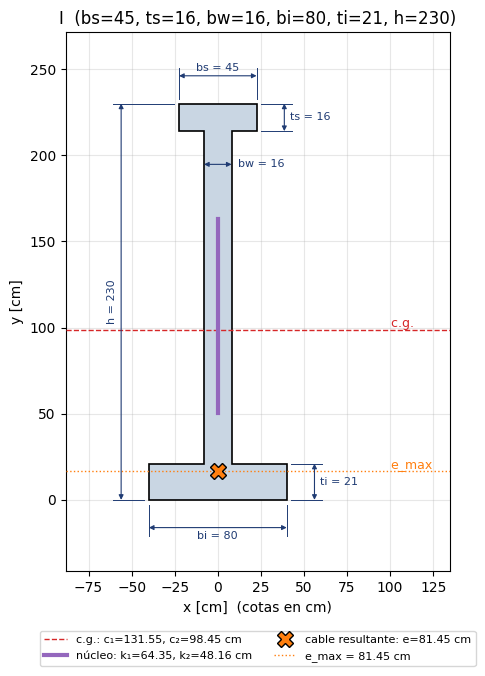

In [8]:
MGc, MTc = res.MG * 100, res.MT * 100   # kg-cm
F_nr = (res.alpha * MTc - MGc) / (res.alpha * (p.k1 + p.k2))
mostrar(f'''
- $\\alpha = \\dfrac{{100}}{{100 - {d.perdidas}}} = $ **{res.alpha:.3f}**
- $e_{{max}} = {p.c2:.2f} - {d.d2:.2f} = $ **{res.emax:.2f} cm**

**Excentricidad no restringida:**

- $F = \\dfrac{{{res.alpha:.3f}({res.MT:,.2f}) - {res.MG:,.2f}}}{{{res.alpha:.3f}({p.k1:.2f} + {p.k2:.2f})}} \\times 10^2 = {F_nr:,.2f}$ kg
- $F_0 = {res.alpha:.3f}({F_nr:,.2f}) = {res.alpha * F_nr:,.2f}$ kg
- $e = \\dfrac{{{res.MG:,.2f} \\times 10^2}}{{{res.alpha * F_nr:,.2f}}} + {p.k2:.2f} = {res.e_no_restr:.2f}$ cm
''')
if not res.restringida:
    mostrar(f'**$e = {res.e:.2f}$ cm $\\le e_{{max}} = {res.emax:.2f}$ cm → CASO UNO: EXCENTRICIDAD NO RESTRINGIDA ✓**')
else:
    mostrar(f'''
**$e = {res.e_no_restr:.2f}$ cm $> e_{{max}} = {res.emax:.2f}$ cm → CASO DOS: EXCENTRICIDAD RESTRINGIDA**

- $F = \\dfrac{{{res.MT:,.2f} \\times 10^2}}{{{res.emax:.2f} + {p.k1:.2f}}} = {res.F:,.2f}$ kg
- $F_0 = {res.alpha:.3f}({res.F:,.2f}) = {res.F0:,.2f}$ kg
- $e = e_{{max}} = {res.e:.2f}$ cm
''')
mostrar(tabla(['Resultado', 'Valor'], [['$F_0$ (inicial)', f'**{res.F0:,.2f} kg**'],
                                       ['$F$ (final)', f'**{res.F:,.2f} kg**'], ['$e$ en L/2', f'**{res.e:.2f} cm**']]))
dibujar_seccion(seccion, res)
plt.show()

## 7. Análisis de la sección en $L/2$

$$f_1 = -\frac{F_0}{A} + \frac{F_0\,e}{S_1} - \frac{M_G}{S_1} \qquad f_2 = -\frac{F_0}{A} - \frac{F_0\,e}{S_2} + \frac{M_G}{S_2} \qquad \text{(inicial; en la final } F,\ M_T)$$

In [9]:
mostrar(desarrollo_esfuerzos(p, res.F0, res.F, res.e, MGc, MTc, res.esfuerzos))


*Etapa inicial ($F_0 + M_G$):*

- $f_1 = -\dfrac{533,539.85}{5,488.00} + \dfrac{(533,539.85)(81.45)}{264,310.74} - \dfrac{20,168,400}{264,310.74} = $ **-9.10 kg/cm²**
- $f_2 = -\dfrac{533,539.85}{5,488.00} - \dfrac{(533,539.85)(81.45)}{353,144.82} + \dfrac{20,168,400}{353,144.82} = $ **-163.17 kg/cm²**

*Etapa final ($F + M_T$):*

- $f_1 = -\dfrac{437,327.75}{5,488.00} + \dfrac{(437,327.75)(81.45)}{264,310.74} - \dfrac{63,763,853}{264,310.74} = $ **-186.16 kg/cm²**
- $f_2 = -\dfrac{437,327.75}{5,488.00} - \dfrac{(437,327.75)(81.45)}{353,144.82} + \dfrac{63,763,853}{353,144.82} = $ **0.00 kg/cm²**


## 8. Verificación de esfuerzos admisibles

| Etapa | Compresión admisible | Tracción admisible |
|---|---|---|
| Inicial ($f'_{ci} = 0.70 f'_c$) | $-0.60\,f'_{ci}$ | **0** |
| Final | $-0.45\,f'_c$ | **0** |

$f'_{ci} = 0.70(420) = 294.00$ kg/cm²

| Etapa | Fibra | f [kg/cm²] | Comp. adm. | Tracc. adm. | Estado |
|---|---|---|---|---|---|
| Inicial | $f_1$ | -9.10 | -176.40 | 0.00 | ✓ Cumple |
| Inicial | $f_2$ | -163.17 | -176.40 | 0.00 | ✓ Cumple |
| Final | $f_1$ | -186.16 | -189.00 | 0.00 | ✓ Cumple |
| Final | $f_2$ | 0.00 | -189.00 | 0.00 | ✓ Cumple |

### ✓ En L/2 la sección CUMPLE con todos los esfuerzos admisibles.

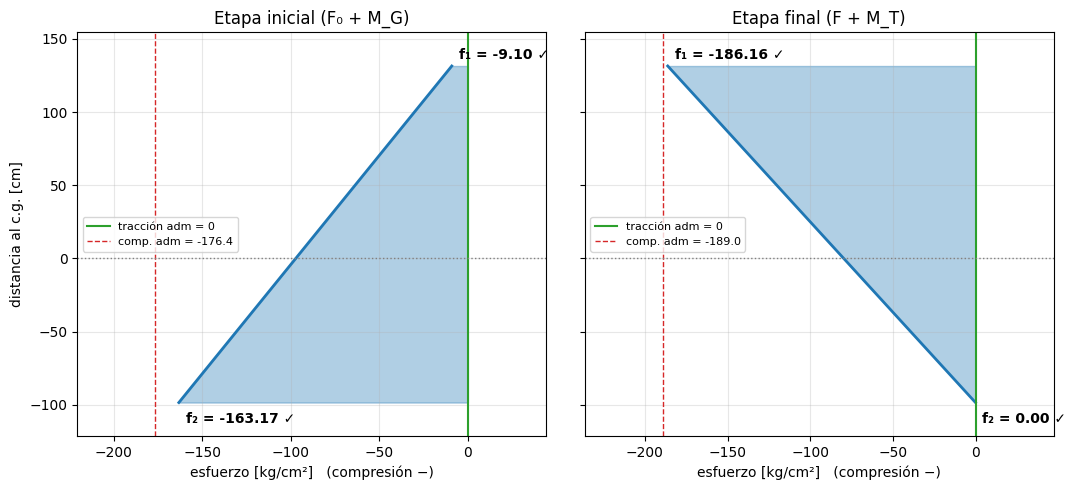

In [10]:
mostrar(f"$f'_{{ci}} = {d.fci_factor:.2f}({d.fc:.0f}) = {res.limites['inicial']['fci']:.2f}$ kg/cm²")
mostrar(tabla_verificacion(res, res.esfuerzos, res.verificacion))
if res.cumple:
    mostrar('### ✓ En L/2 la sección CUMPLE con todos los esfuerzos admisibles.')
else:
    mostrar('### ✗ En L/2 la sección NO CUMPLE. **Rediseñe la sección** (normalmente aumentando la altura).')
dibujar_esfuerzos(res)
plt.show()

## 9. Eficiencia de la sección

$$Q = \frac{k_1 + k_2}{h} = \frac{r^2}{c_1\,c_2} \qquad Q = 0.50 \text{ eficiente} \quad Q < 0.45 \text{ pesada} \quad Q > 0.55 \text{ demasiado esbelta}$$

In [11]:
mostrar(f'''
- $Q = \\dfrac{{{p.k1:.2f} + {p.k2:.2f}}}{{{p.h:.2f}}} = $ **{res.Q:.3f}**  ·  comprobación: $\\dfrac{{r^2}}{{c_1 c_2}} = \\dfrac{{{p.r2:,.2f}}}{{({p.c1:.2f})({p.c2:.2f})}} = {res.Q_r2:.3f}$

### {'✓' if 0.45 <= res.Q <= 0.55 else '⚠'} {res.Q_estado}
''')


- $Q = \dfrac{64.35 + 48.16}{230.00} = $ **0.489**  ·  comprobación: $\dfrac{r^2}{c_1 c_2} = \dfrac{6,335.42}{(131.55)(98.45)} = 0.489$

### ✓ DISEÑO EFICIENTE (0.45 ≤ Q ≤ 0.55, óptimo Q = 0.50)


## 10. Registro de iteraciones

Resultado de la **iteración actual** (todo lo calculado hasta $Q$). Presione **Guardar iteración** para agregarla al registro (`Iteraciones/iteraciones.json`): queda guardada aunque cierre VS Code, y la tabla resumen se actualiza al instante.
Si guarda dos veces la misma sección, no se duplica.

In [12]:
reg = Registro('Iteraciones/iteraciones.json')
mostrar(veredicto_md(res))
for aviso in reg.avisos_datos(datos):
    mostrar('⚠ ' + aviso)


def registro_md():
    return '### Resumen de iteraciones guardadas\n\n' + reg.resumen_md()


n_guardada = reg.buscar(seccion, datos)
aviso_estado = (f'Esta sección ya está guardada como <b>iteración {n_guardada}</b>.' if n_guardada else
                f'Sección actual <b>sin guardar</b> (sería la iteración {len(reg.iteraciones) + 1}).')
if HAY_WIDGETS:
    estado = widgets.HTML(aviso_estado)
    boton = widgets.Button(description='Guardar iteración', icon='save', button_style='success',
                           layout=widgets.Layout(width='200px'))
    display(widgets.HBox([boton, estado]))
    tabla_registro = display(Markdown(registro_md()), display_id=True)

    def al_guardar(_):
        estado.value = reg.guardar(seccion, datos, res)
        tabla_registro.update(Markdown(registro_md()))

    boton.on_click(al_guardar)
else:
    mostrar(aviso_estado.replace('<b>', '**').replace('</b>', '**') +
            ' El botón necesita **ipywidgets**: guarde con `reg.guardar(seccion, datos, res)` en la celda siguiente.')
    mostrar(registro_md())

### ✓ La sección CUMPLE con los esfuerzos admisibles de f₁ y f₂.

Eficiencia: $Q$ = 0.489 → ✓ DISEÑO EFICIENTE (0.45 ≤ Q ≤ 0.55, óptimo Q = 0.50)

### Resumen de iteraciones guardadas

| N° | Sección | A [cm²] | q_G [kg/m] | Excentricidad | F₀ [kg] | F [kg] | e [cm] | f₁ ini | f₂ ini | f₁ fin | f₂ fin | Q | Estado |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | T  (B=40, t=16, bw=16, h=230) | 4,064 | 975.4 | No restringida | 647,858 | 531,031 | 70.47 | 0.00 | **-349.56** ✗ | **-240.22** ✗ | 0.00 | 0.379 | ✗ No cumple |
| 2 | I  (bs=45, ts=16, bw=16, bi=80, ti=21, h=230) | 5,488 | 1,317.1 | Restringida | 533,540 | 437,328 | 81.45 | -9.10 | -163.17 | -186.16 | 0.00 | 0.489 | ✓ Cumple · **adoptada** |

Admisibles: inicial -176.40 ≤ f ≤ 0 · final -189.00 ≤ f ≤ 0 [kg/cm²]. Valores en **negrita ✗** no cumplen.

Opciones del registro (descomente la línea que necesite y ejecute **solo esta celda**):

In [13]:
#print(reg.guardar(seccion, datos, res))   # guardar la iteración actual sin el botón
#print(reg.borrar(2))                      # borrar la iteración 2 (las demás se renumeran)
#print(reg.nuevo())                        # vaciar el registro para empezar un diseño nuevo

In [14]:
if not res.cumple:
    detener('■ La sección actual NO CUMPLE los esfuerzos admisibles: el diseño se detiene aquí.\n'
            '  Guarde la iteración (paso 10), modifique la sección (paso 3) y vuelva a ejecutar (Run All).')
mostrar('### ✓ La sección cumple: se continúa con el cable resultante, las curvas límite y los torones.')

### ✓ La sección cumple: se continúa con el cable resultante, las curvas límite y los torones.

## 11. Cable resultante y curvas límite

El cable resultante es una **parábola** que pasa por $e$ en el centro de la luz y por el **c.g.** en los apoyos.
Con origen en el centro de la luz ($X = x - L/2$):

$$y = k\,X^2 \qquad k = \frac{e}{(L/2)^2} \qquad e(x) = e\,\frac{4x(L-x)}{L^2} \qquad \alpha = k\,L \;\text{(ángulo de salida)}$$

**Curvas límite** (con $F_0$ y $F$ del centro de la luz, constantes):

$$e_{ini}(x) = k_2 + \frac{M_G(x)}{F_0} \;\;(f_1 = 0) \qquad\qquad e_{fin}(x) = \frac{M_T(x)}{F} - k_1 \;\;(f_2 = 0)$$

Si $e_{fin}(x) \le e(x) \le e_{ini}(x)$, las fibras extremas trabajan a compresión en ambas etapas.
Casos: curvas **tangentes** (el cable debe pasar por el punto de tangencia), con **holgura**, o que **se cortan** (puntos A y B).


- $k = \dfrac{0.8145\ \text{m}}{(17.50\ \text{m})^2} = $ **0.002660 m⁻¹**  →  $y = 0.002660\,X^2$
- $\alpha = k\,L = (0.002660)(35.00) = $ **0.0931 rad = 5.33°**
- En $L/2$: $e_{ini} = 48.16 + \dfrac{20,168,400}{533,539.85} = 85.96$ cm  ·  $e_{fin} = \dfrac{63,763,853}{437,327.75} - 64.35 = 81.45$ cm

**Caso: HOLGURA.** Las curvas límite no se cortan: existe una zona admisible para el cable en toda la luz (holgura en L/2 = 4.51 cm).

### ✓ El cable resultante queda entre las curvas límite en toda la viga.


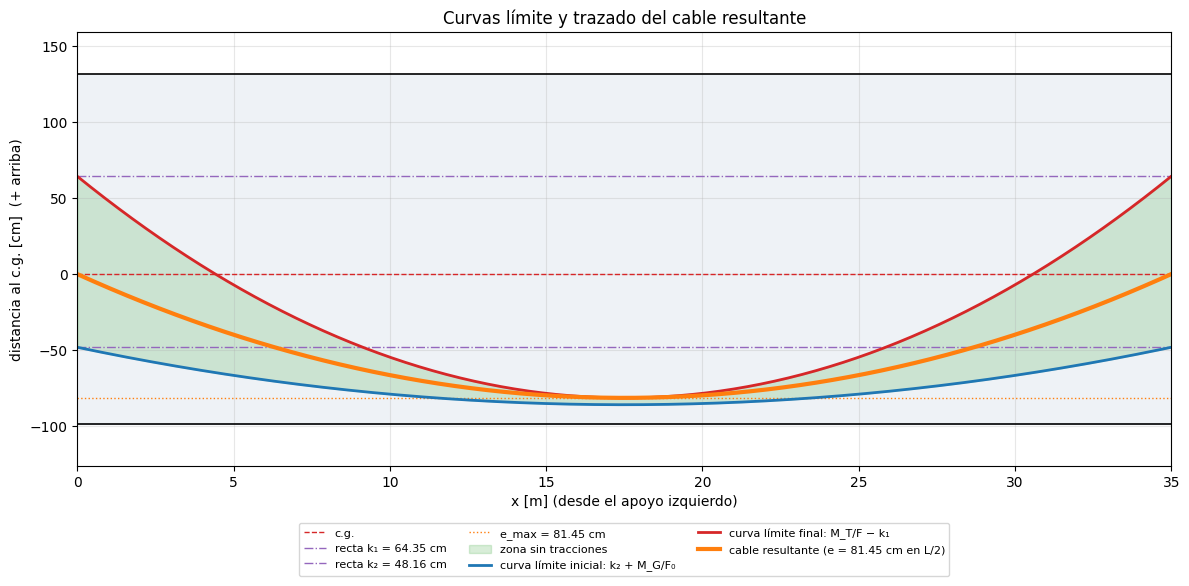

In [15]:
cl = curvas_limite(res)
mostrar(f'''
- $k = \\dfrac{{{res.e / 100:.4f}\\ \\text{{m}}}}{{({d.L / 2:.2f}\\ \\text{{m}})^2}} = $ **{res.k_parabola:.6f} m⁻¹**  →  $y = {res.k_parabola:.6f}\\,X^2$
- $\\alpha = k\\,L = ({res.k_parabola:.6f})({d.L:.2f}) = $ **{res.angulo_salida:.4f} rad = {res.angulo_salida * 57.29578:.2f}°**
- En $L/2$: $e_{{ini}} = {p.k2:.2f} + \\dfrac{{{MGc:,.0f}}}{{{res.F0:,.2f}}} = {float(res.e_lim_inicial(d.L / 2)):.2f}$ cm  ·  $e_{{fin}} = \\dfrac{{{MTc:,.0f}}}{{{res.F:,.2f}}} - {p.k1:.2f} = {float(res.e_lim_final(d.L / 2)):.2f}$ cm

**Caso: {cl.caso.upper()}.** {cl.descripcion}

### {'✓ El cable resultante queda entre las curvas límite en toda la viga.' if cl.cable_entre_curvas else '✗ El cable resultante sale de la zona admisible.'}
''')
dibujar_curvas_limite(res)
plt.show()

## 12. Torones (modo manual)

Escriba la posición de **cada torón** en el centro de la luz y en el apoyo (cm, **y desde la fibra inferior**):

`toron(x_centro, y_centro, x_apoyo=None, y_apoyo=...)` — si no da `x_apoyo`, el torón no se desvía en planta.

Todos los torones llevan la misma fuerza ($F/n$), así que la **resultante es el promedio** de sus posiciones y debe coincidir con
el cable resultante. Cada torón sigue la parábola $y_i = y_{i,c} + k_i X^2$, con $k_i = (y_{i,a} - y_{i,c})/(L/2)^2$ y $\alpha_i = k_i L$.

In [16]:
mostrar(f'''
**Objetivo para la resultante de los torones:**
- En el centro de la luz: $\\bar y_c = \\bar y - e = {p.yc:.2f} - {res.e:.2f} = $ **{p.yc - res.e:.2f} cm**
- En el apoyo (c.g.): $\\bar y_a = \\bar y = $ **{p.yc:.2f} cm**
''')


**Objetivo para la resultante de los torones:**
- En el centro de la luz: $\bar y_c = \bar y - e = 98.45 - 81.45 = $ **17.00 cm**
- En el apoyo (c.g.): $\bar y_a = \bar y = $ **98.45 cm**


| Torón | $x_c$ | $y_c$ | $e_c$ | $x_a$ | $y_a$ | $e_a$ | $k_i$ [m⁻¹] | $\alpha_i$ [°] | Dentro |
|---|---|---|---|---|---|---|---|---|---|
| 1 | -4.0 | 10.00 | 88.45 | -4.0 | 84.45 | 14.00 | 0.002431 | 4.88 | ✓ |
| 2 | 4.0 | 10.00 | 88.45 | 4.0 | 84.45 | 14.00 | 0.002431 | 4.88 | ✓ |
| 3 | -4.0 | 24.00 | 74.45 | -4.0 | 112.45 | -14.00 | 0.002888 | 5.79 | ✓ |
| 4 | 4.0 | 24.00 | 74.45 | 4.0 | 112.45 | -14.00 | 0.002888 | 5.79 | ✓ |


**n = 4 torones**

- Centro de la luz: $\bar y_c = \dfrac{\Sigma y_{i,c}}{n} = 17.00$ cm → $e_{res} = 98.45 - 17.00 = 81.45$ cm (diseño $e = 81.45$ cm, Δ = +0.000 cm)
- Apoyo: $\bar y_a = 98.45$ cm → $e_{res} = 0.00$ cm (debe ser 0, Δ = +0.005 cm)

### ✓ Resultante coincide con el cable resultante (±0.5 cm)  ·  ✓ todos los torones dentro del hormigón


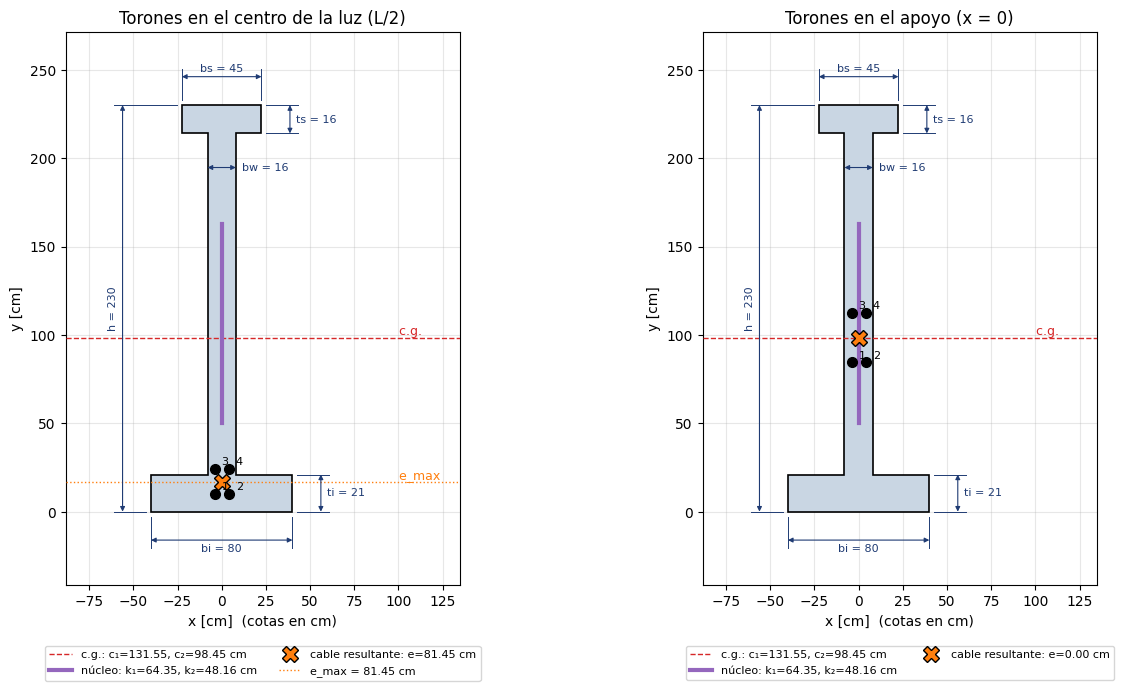

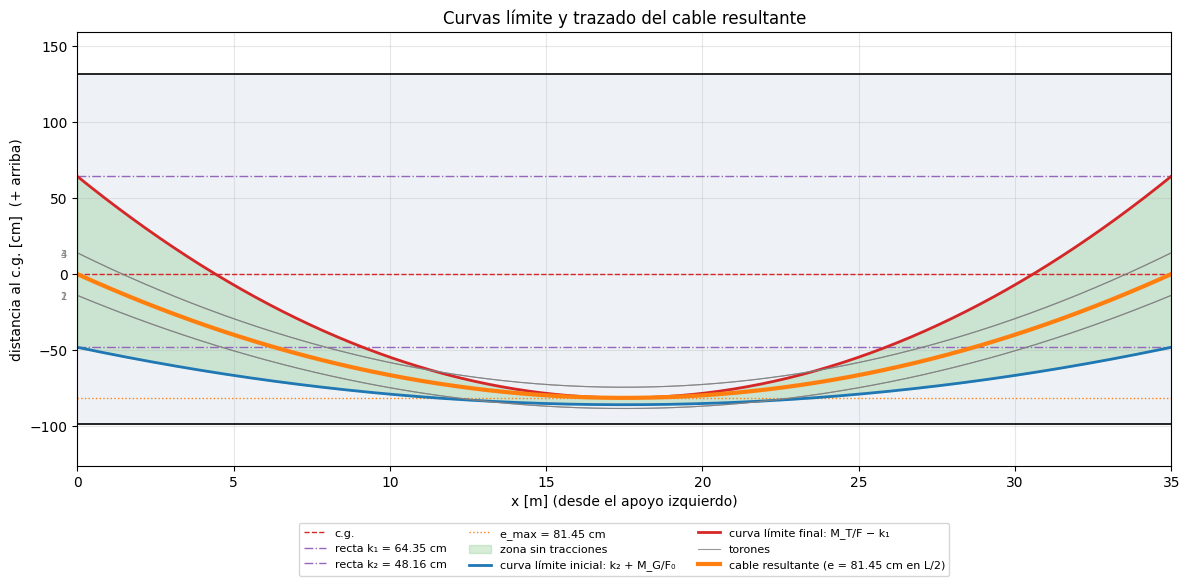

In [17]:
torones = [
    #     x_c   y_c          y_apoyo
    toron(-4,   10, y_apoyo=  84.45),
    toron( 4,   10, y_apoyo=  84.45),
    toron(-4,   24, y_apoyo= 112.45),
    toron( 4,   24, y_apoyo= 112.45),
]
TOLERANCIA = 0.5   # [cm] diferencia admitida entre la resultante y el cable resultante

rt = verificar_torones(seccion, res, torones, TOLERANCIA)
mostrar(tabla(['Torón', '$x_c$', '$y_c$', '$e_c$', '$x_a$', '$y_a$', '$e_a$', '$k_i$ [m⁻¹]', '$\\alpha_i$ [°]', 'Dentro'],
              [[t['i'], f"{t['t'].x_centro:.1f}", f"{t['t'].y_centro:.2f}", f"{t['e_c']:.2f}",
                f"{t['t'].x_apoyo:.1f}", f"{t['t'].y_apoyo:.2f}", f"{t['e_a']:.2f}",
                f"{t['k']:.6f}", f"{t['alpha_deg']:.2f}", '✓' if t['dentro'] else '✗'] for t in rt.detalle]))
mostrar(f'''
**n = {rt.n} torones**

- Centro de la luz: $\\bar y_c = \\dfrac{{\\Sigma y_{{i,c}}}}{{n}} = {rt.y_res_centro:.2f}$ cm → $e_{{res}} = {p.yc:.2f} - {rt.y_res_centro:.2f} = {rt.e_res_centro:.2f}$ cm (diseño $e = {res.e:.2f}$ cm, Δ = {rt.dif_centro:+.3f} cm)
- Apoyo: $\\bar y_a = {rt.y_res_apoyo:.2f}$ cm → $e_{{res}} = {rt.e_res_apoyo:.2f}$ cm (debe ser 0, Δ = {rt.dif_apoyo:+.3f} cm)

### {'✓' if rt.resultante_ok else '✗'} Resultante {'coincide' if rt.resultante_ok else 'NO coincide'} con el cable resultante (±{TOLERANCIA} cm)  ·  {'✓ todos los torones dentro del hormigón' if rt.dentro_ok else '✗ hay torones fuera del hormigón (en rojo)'}
''')
dibujar_torones(seccion, res, torones)
plt.show()
dibujar_curvas_limite(res, torones=torones)
plt.show()

## 13. Validez del diseño

In [18]:
checks = [
    ('Esfuerzos admisibles en L/2 (tracción = 0)', res.cumple, 'Obligatoria'),
    ('Cable resultante entre las curvas límite', cl.cable_entre_curvas, 'Obligatoria'),
    ('Resultante de los torones = cable resultante', rt.resultante_ok, 'Obligatoria'),
    ('Torones dentro del hormigón', rt.dentro_ok, 'Obligatoria'),
    ('Eficiencia 0.45 ≤ Q ≤ 0.55', 0.45 <= res.Q <= 0.55, 'Recomendación'),
    ('A ≥ A_c requerida (predimensionamiento)', p.A >= pre.Ac_req, 'Recomendación'),
    ('Sección adoptada guardada en el registro de iteraciones', reg.buscar(seccion, datos) is not None, 'Recomendación'),
]
mostrar(tabla(['Verificación', 'Tipo', 'Estado'], [[c, t, '✓ Cumple' if ok else '✗ **No cumple**'] for c, ok, t in checks]))
valido = all(ok for _, ok, t in checks if t == 'Obligatoria')
mostrar('## ✓ DISEÑO VÁLIDO' if valido else '## ✗ DISEÑO NO VÁLIDO: revise las verificaciones obligatorias y rediseñe.')

| Verificación | Tipo | Estado |
|---|---|---|
| Esfuerzos admisibles en L/2 (tracción = 0) | Obligatoria | ✓ Cumple |
| Cable resultante entre las curvas límite | Obligatoria | ✓ Cumple |
| Resultante de los torones = cable resultante | Obligatoria | ✓ Cumple |
| Torones dentro del hormigón | Obligatoria | ✓ Cumple |
| Eficiencia 0.45 ≤ Q ≤ 0.55 | Recomendación | ✓ Cumple |
| A ≥ A_c requerida (predimensionamiento) | Recomendación | ✓ Cumple |
| Sección adoptada guardada en el registro de iteraciones | Recomendación | ✓ Cumple |

## ✓ DISEÑO VÁLIDO

## 14. Informe en LaTeX

Genera la memoria de cálculo completa en la carpeta `Informe/` (`.tex` y `.pdf`; las figuras van a `Figuras/`): predimensionamiento,
**iteraciones de la sección**, sección adoptada, diseño, verificaciones, eficiencia, cable, curvas límite, torones y conclusión.
Ponga `GENERAR_INFORME = False` si no quiere generarlo en cada ejecución.

In [19]:
import generar_informe as gi
importlib.reload(gi)

GENERAR_INFORME = True
TITULO = "Diseño de viga de hormigón presforzado"

if GENERAR_INFORME:
    if reg.buscar(seccion, datos) is None:
        mostrar('⚠ **La sección actual no está guardada** en el registro: guárdela (paso 10) para que el '
                'informe la muestre como iteración adoptada.')
    if not valido:
        mostrar('⚠ **El diseño no es válido**: el informe se genera igual e indicará qué debe corregirse.')
    ruta_tex = gi.generar_informe(seccion, datos, torones,
                                  carpeta="Informe", titulo=TITULO, tolerancia=TOLERANCIA,
                                  iteraciones=reg.iteraciones)

LaTeX generado: Informe/Informe_Viga_Presforzada.tex


PDF generado:   Informe/Informe_Viga_Presforzada.pdf
